# Label noise: which boxes carry a class that their neighbouring photos do not share?

This notebook tests the `label_noise` check of DataCopilot on **real photos** (COCO128) with **real DINOv2-small embeddings**.
Real label mistakes are not known for this sample, so we plant some: a seeded share of the boxes gets a wrong class, and we
measure how many of those the check finds (recall), how many of what it reports are really planted (precision), and how many
untouched boxes it reports anyway (false-positive rate).

The check is a lead generator, not a judge. It looks at the photo-level embedding the audit already has, not at the box itself,
so we expect it to be weak on a dataset like this one. **The numbers computed below decide how the result is described.**
Every number on this page is computed by the cell above it; the text written by hand contains no results.

> **Recorded with the whole-image rule (Phase 6).** Since then `label_noise` embeds box crops by default and keeps this rule as `suspect_basis="image"` and as its reported fallback. The saved outputs below are the record of the whole-image rule; re-running this notebook as it is would apply the crop rule in its command-line cells. Notebook 05 measures both rules on the same seeds, and checks that the whole-image rule still gives the numbers saved here.

**About the data and its licence.** The photos come from COCO (train2017) through the COCO128 sample published by Ultralytics.
The COCO annotations are licensed CC BY 4.0, and each image keeps the licence of its original Flickr owner. The notebook
downloads the sample at run time into a cache folder outside the repository and never copies, commits or redistributes an image.

### Set-up

The next cell prepares a clean work folder and defines `datacopilot(...)`, which runs a real DataCopilot command exactly as a
terminal would and prints the command, its output and its exit code.

In [1]:
import hashlib
import json
import os
import shlex
import shutil
import subprocess
import sys
import tempfile
import time
import types
import urllib.request
import warnings
import zipfile
from pathlib import Path

# Where downloads are cached (outside the repository) and where this notebook works.
# A private folder that only this user can enter (not a shared, predictable path in the temp folder);
# set DATACOPILOT_NOTEBOOK_DATA to keep the download between runs.
DATA = Path(
    os.environ.get("DATACOPILOT_NOTEBOOK_DATA") or tempfile.mkdtemp(prefix="datacopilot-nb-")
).resolve()
WORK = DATA / "work-label-noise"
shutil.rmtree(WORK, ignore_errors=True)  # start clean, so the notebook can be re-run from the top
WORK.mkdir(parents=True)
os.chdir(WORK)  # everything below uses paths relative to this folder

# Printing helper: hide the folders of this machine behind short placeholders.
_HIDE = [
    (str(p), name)
    for p, name in [
        (WORK, "<work>"),
        (WORK.resolve(), "<work>"),
        (DATA, "<data>"),
        (DATA.resolve(), "<data>"),
        (Path(tempfile.gettempdir()), "<tmp>"),
        (Path(tempfile.gettempdir()).resolve(), "<tmp>"),
        (Path.home(), "~"),
    ]
]
_HIDE.sort(key=lambda pair: -len(pair[0]))


def tidy(text):
    for real, placeholder in _HIDE:
        text = text.replace(real, placeholder)
    return text


class Done(types.SimpleNamespace):
    """What a command returned (shows nothing when it ends a cell)."""

    def _ipython_display_(self):
        pass


def datacopilot(*args, env=None, timed=False):
    """Run one `datacopilot` command like a terminal: show the command, what it prints and its exit code."""
    start = time.perf_counter()
    done = subprocess.run(  # noqa: S603  (our own command, no shell)
        [
            sys.executable,
            "-I",
            "-m",
            "datacopilot",
            *map(str, args),
        ],  # -I: no current-folder or PYTHON* imports
        capture_output=True,
        text=True,
        timeout=3600,
        env={**os.environ, "TQDM_DISABLE": "1", "HF_HUB_DISABLE_PROGRESS_BARS": "1", **(env or {})},
    )
    seconds = time.perf_counter() - start
    done.messages = [
        tidy(line) for line in done.stderr.splitlines() if line.strip() and not line.startswith("{")
    ]
    print("$ datacopilot " + " ".join(shlex.quote(str(a)) for a in args))
    for line in done.stdout.splitlines():
        print(tidy(line)[:240])
    for line in done.messages:
        print("[message]", line[:400])
    print(f"[exit code {done.returncode}" + (f", {seconds:.1f} s]" if timed else "]"))
    return Done(
        returncode=done.returncode,
        stdout=done.stdout,
        stderr=done.stderr,
        messages=done.messages,
        seconds=seconds,
    )


def latest_report(name="report.json"):
    """The report the last audit wrote next to us (JSON version)."""
    return json.loads(Path(name).read_text())


os.environ["DATACOPILOT_LOG_LEVEL"] = "ERROR"  # keep the technical JSON log lines out of this page
os.environ["TQDM_DISABLE"] = os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = (
    "1"  # no progress bars on this page
)
warnings.filterwarnings("ignore")
print("cache folder :", tidy(str(DATA)))
print("work folder  :", tidy(str(WORK)))
print("python       :", sys.version.split()[0])

cache folder : <data>
work folder  : <work>
python       : 3.13.9


**What this shows.** Every file this notebook creates lives in the work folder; paths printed below are relative to it.

## 1. Download the real photos, verified

The cell below downloads the COCO128 zip (once), compares its SHA-256 with the pinned value **before** anything is unpacked,
and unpacks it with every entry checked (no absolute paths, no `..`, no links, bounded size, file count and compression ratio).
The checksum is the one pinned and cross-checked in the first notebook; if the file ever changes, the cell stops and deletes it.
The model needs no pin here: DataCopilot's own registry fixes DINOv2-small to one commit and verifies the SHA-256 of its
`.safetensors` weights before loading them. No pickle file is opened.

In [2]:
# Pinned fingerprint of the one file we download (see the note above this cell for where it came from).
COCO128_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"
COCO128_SHA256 = "61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e"
COCO128_BYTES = 6_983_030
MAX_DOWNLOAD_BYTES = 50_000_000  # refuse anything bigger than this, whatever the server says
MAX_FILES, MAX_UNPACKED_BYTES, MAX_RATIO = 1_000, 100_000_000, 20


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def fetch_coco128():
    """Download COCO128 (HTTPS only, bounded, atomic); return its path once the pinned checksum matches."""
    if not COCO128_URL.startswith("https://"):
        raise RuntimeError("downloads must use HTTPS")
    DATA.mkdir(parents=True, exist_ok=True)
    target = DATA / "coco128.zip"
    if target.exists() and sha256_of(target) != COCO128_SHA256:
        target.unlink()  # never reuse a cached file whose checksum is wrong
    if not target.exists():
        partial = target.with_suffix(".part")
        try:
            with (
                urllib.request.urlopen(COCO128_URL, timeout=60) as reply,
                open(partial, "wb") as out,
            ):  # noqa: S310
                if int(reply.headers.get("Content-Length") or 0) > MAX_DOWNLOAD_BYTES:
                    raise RuntimeError("the server announced a file that is too big")
                received = 0
                for block in iter(lambda: reply.read(1 << 20), b""):
                    received += len(block)
                    if received > MAX_DOWNLOAD_BYTES:
                        raise RuntimeError("download is larger than the allowed maximum")
                    out.write(block)
        except OSError as problem:
            partial.unlink(missing_ok=True)
            raise RuntimeError(
                "Could not download COCO128 (" + type(problem).__name__ + "). "
                "These notebooks need the network once to fetch about 7 MB from "
                + COCO128_URL
                + ". "
                "Connect and run this cell again, or download that file yourself and save it as "
                "'coco128.zip' in the cache folder (set DATACOPILOT_NOTEBOOK_DATA to choose where it is)."
            ) from None
        except RuntimeError:
            partial.unlink(missing_ok=True)
            raise
        actual = sha256_of(partial)
        if actual != COCO128_SHA256:
            partial.unlink()
            raise RuntimeError(
                "COCO128 checksum mismatch (got "
                + actual
                + "); the file was deleted and nothing was unpacked"
            )
        partial.replace(target)  # atomic: a half-written file never carries the final name
    return target


def unpack_safely(archive_path, destination):
    """Unpack a zip we do not trust: check every entry first, then write into a fresh folder."""
    destination = Path(destination)
    if destination.exists():
        raise RuntimeError("the destination must be a fresh folder")
    with zipfile.ZipFile(archive_path) as archive:
        members = archive.infolist()
        if len(members) > MAX_FILES or sum(m.file_size for m in members) > MAX_UNPACKED_BYTES:
            raise RuntimeError("archive has too many files or unpacks to too much data")
        for member in members:
            name = member.filename
            is_link = ((member.external_attr >> 16) & 0o170000) == 0o120000
            if (
                name.startswith(("/", chr(92)))
                or ".." in Path(name).parts
                or ":" in name
                or is_link
            ):
                raise RuntimeError("unsafe entry in the archive: " + name)
            if member.compress_size and member.file_size / member.compress_size > MAX_RATIO:
                raise RuntimeError("suspiciously high compression ratio for " + name)
        for member in members:  # every entry passed; now write them one by one
            path = destination / member.filename
            if member.is_dir():
                path.mkdir(parents=True, exist_ok=True)
                continue
            path.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member) as source_file, open(path, "wb") as out:
                shutil.copyfileobj(source_file, out)
    return destination


zip_path = fetch_coco128()
print("file    :", zip_path.name, f"({zip_path.stat().st_size / 1e6:.1f} MB)")
print("sha256  :", sha256_of(zip_path))
print(
    "checksum matches the pinned value: True (a mismatch stops the notebook before anything is unpacked)"
)

raw = unpack_safely(zip_path, "raw")
print("images  :", len(list((raw / "coco128/images/train2017").glob("*.jpg"))))
print("labels  :", len(list((raw / "coco128/labels/train2017").glob("*.txt"))))

file    : coco128.zip (7.0 MB)
sha256  : 61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e
checksum matches the pinned value: True (a mismatch stops the notebook before anything is unpacked)
images  : 128
labels  : 128


**What this shows.** The archive matched the pinned checksum before it was opened, and holds one label file per photo.

In [3]:
# COCO128 is one folder of 128 photos with no list of class names and no validation split, so we
# add both: the 80 official COCO class names, and every fifth photo (sorted by name) becomes "val".
NAMES = [
    n.replace("_", " ")
    for n in "person bicycle car motorcycle airplane bus train truck boat traffic_light fire_hydrant stop_sign parking_meter bench bird cat dog horse sheep cow elephant bear zebra giraffe backpack umbrella handbag tie suitcase frisbee skis snowboard sports_ball kite baseball_bat baseball_glove skateboard surfboard tennis_racket bottle wine_glass cup fork knife spoon bowl banana apple sandwich orange broccoli carrot hot_dog pizza donut cake chair couch potted_plant bed dining_table toilet tv laptop mouse remote keyboard cell_phone microwave oven toaster sink refrigerator book clock vase scissors teddy_bear hair_drier toothbrush".split()
]
if len(NAMES) != 80:
    raise ValueError("expected the 80 COCO class names")


def build_yolo_layout(target="coco128"):
    """Copy the raw COCO128 files into the folder layout DataCopilot's YOLO reader expects."""
    target = Path(target)
    source = raw / "coco128"
    photos = sorted((source / "images/train2017").glob("*.jpg"))
    for number, photo in enumerate(photos):
        split = "val" if number % 5 == 4 else "train"
        (target / "images" / split).mkdir(parents=True, exist_ok=True)
        (target / "labels" / split).mkdir(parents=True, exist_ok=True)
        shutil.copy(photo, target / "images" / split / photo.name)
        label = source / "labels/train2017" / (photo.stem + ".txt")
        if label.exists():
            shutil.copy(label, target / "labels" / split / label.name)
    names = ", ".join(json.dumps(n) for n in NAMES)
    (target / "data.yaml").write_text(
        f"path: .\ntrain: images/train\nval: images/val\nnc: 80\nnames: [{names}]\n"
    )
    return target


build_yolo_layout("coco128")
print(sorted(p.name for p in Path("coco128").iterdir()))
print("train photos:", len(list(Path("coco128/images/train").glob("*.jpg"))))
print("val photos  :", len(list(Path("coco128/images/val").glob("*.jpg"))))

['data.yaml', 'images', 'labels']
train photos: 103
val photos  : 25


**What this shows.** The photos are arranged in the folder layout DataCopilot's YOLO reader expects, with the 80 official COCO class names.

## 2. The dataset, and the real embeddings

`ingest` turns the folder into a versioned `.dcp` dataset. `embed` runs the real DINOv2-small model once over every photo and
caches the vectors inside the dataset. Both are ordinary commands.

In [4]:
from collections import Counter

ingest = datacopilot("ingest", "coco128", "--format", "yolo", "-o", "coco128.dcp")
embed = datacopilot("embed", "coco128.dcp", "--embedder", "dinov2_small", timed=True)
EMBED_SECONDS = embed.seconds

$ datacopilot ingest coco128 --format yolo -o coco128.dcp
d9105ffb854e7dbeccf255a4848bd692
[exit code 0]


$ datacopilot embed coco128.dcp --embedder dinov2_small
embedded=128 total=128 cached=0 missing=0 model=dinov2_small@ed25f3a31f01 run_id=99c6c5b2-d222-432b-a71f-e48fed970675
[exit code 0, 6.6 s]


**What this shows.** The first line is the dataset version, the second the number of photos embedded, the model and the exact
commit of the pinned weights (a prefix of it), and the exit code of each command.

In [5]:
import datacopilot as dc

clean = dc.load("coco128.dcp")
name_of = {c.id: c.name for c in clean.categories}
per_class = Counter(a.category_id for a in clean.annotations)
per_image = Counter(a.image_id for a in clean.annotations)
print("photos                 :", len(clean.images))
print("boxes                  :", len(clean.annotations))
print("classes used / defined :", len(per_class), "/", len(name_of))
print("photos with 1 box      :", sum(1 for n in per_image.values() if n == 1))
print("photos with 5+ boxes   :", sum(1 for n in per_image.values() if n >= 5))
top = per_class.most_common(3)
print("most common classes    :", ", ".join(f"{name_of[c]} {n}" for c, n in top))
print("classes with 1 box     :", sum(1 for n in per_class.values() if n == 1))

photos                 : 128
boxes                  : 929
classes used / defined : 71 / 80
photos with 1 box      : 12
photos with 5+ boxes   : 60
most common classes    : person 254, car 46, cup 36
classes with 1 box     : 4


**What this shows.** The shape of the data decides what an image-level check can do: how many boxes there are, how many
classes, how concentrated they are, and how many classes appear only once.

## 3. The check on the untouched dataset, through the command line

`label_noise` joins `--checks all` when an embedder is given. Here it runs alone on the clean dataset with the default
thresholds, reading the cached embeddings, and writes the three report formats.

In [6]:
audit = datacopilot(
    "audit",
    "coco128.dcp",
    "--checks",
    "label_noise",
    "--embedder",
    "dinov2_small",
    "--no-hash-cache",
    "--fail-on",
    "none",
    "--json",
    "clean.json",
    "--report",
    "clean.html",
    "--sarif",
    "clean.sarif",
)
report = json.loads(Path("clean.json").read_text())
by_rule = Counter(f["payload"]["rule"] for f in report["findings"])
print("findings by rule:", dict(sorted(by_rule.items())))
print("severities      :", report["counts"])
for f in report["findings"]:
    if f["payload"]["rule"] in ("annotations_not_scored", "suspects_truncated"):
        print(f["payload"])

$ datacopilot audit coco128.dcp --checks label_noise --embedder dinov2_small --no-hash-cache --fail-on none --json clean.json --report clean.html --sarif clean.sarif
passed critical=1 warn=0 info=29 run_id=04b496d8-1573-4ef1-aff4-fe30244d8896
[exit code 0]
findings by rule: {'annotations_not_scored': 1, 'suspect_class': 28, 'suspects_truncated': 1}
severities      : {'critical': 1, 'info': 29, 'warn': 0}
{'count': 633, 'min_neighbours': 3, 'min_similarity': 0.3, 'rule': 'annotations_not_scored', 'total': 929}
{'count': 62, 'rule': 'suspects_truncated'}


**What this shows.** What the check says about data nobody damaged: its leads, how many boxes it could not score at all
(too few close neighbours) and how many leads it hid behind the per-image and per-class caps. Both counts are reported, never dropped silently.

In [7]:
html = Path("clean.html").read_text()
sarif = json.loads(Path("clean.sarif").read_text())
rule_ids = sorted({r["ruleId"] for run in sarif["runs"] for r in run["results"]})
print("SARIF rule ids   :", rule_ids)
print(
    "HTML mentions the rule text :",
    "Annotation class disagrees with its neighbouring images" in html,
)
print(
    "no absolute path in any report :",
    not any(str(WORK) in Path(p).read_text() for p in ("clean.json", "clean.html", "clean.sarif")),
)

SARIF rule ids   : ['label_noise/annotations_not_scored', 'label_noise/suspect_class', 'label_noise/suspects_truncated']
HTML mentions the rule text : True
no absolute path in any report : True


**What this shows.** The same findings appear in the HTML and SARIF reports under the rule id `label_noise/suspect_class`,
and none of the reports contains a folder of this machine.

## 4. Plant mistakes and measure

The protocol is fixed before looking at any result. A seeded random generator picks a fixed share of the boxes (`RATE`, printed with the results below) and gives each a
new class chosen uniformly among the **other classes that occur in the dataset**. The photos are not touched, so the embeddings are the
same; only the labels change. We repeat this for five seeds. A box is **found** when the check reports it as `suspect_class`.

The check cannot score a box whose photo has too few close neighbours (`annotations_not_scored`). Such a box is **not a miss of the rule**, but it is
a mistake the check cannot see, so every measure is given over two denominators: **all boxes**, and **scorable boxes** (the ones the check scored).

- precision = found / reported
- recall = found / planted, over all boxes; and found / planted-and-scorable, over scorable boxes
- false-positive rate = reported but not planted / boxes that were not planted, over all boxes; and over scorable boxes
- the **base rate** is the planted share: a check that reported boxes at random would have that precision. It is given over all boxes and over scorable boxes.

The two caps of the check (per image, per class) hide reports, so the measurement lifts them; the capped view follows afterwards.
The in-process runs reuse the verified embeddings the command line cached above, through the audit's own embedding pipeline.

In [8]:
import uuid

import numpy as np

from datacopilot.audit import engine
from datacopilot.audit.context import CheckConfig, CheckContext
from datacopilot.audit.embedding import PipelineProvider
from datacopilot.audit.usecase import resolve_embedder
from datacopilot.core.schema import Dataset
from datacopilot.settings import load_settings

DEFAULT = CheckConfig()
SEEDS = (0, 1, 2, 3, 4)
RATE = 0.05
settings = load_settings()
embedder = resolve_embedder("dinov2_small", settings.allowed_licenses)
print("planted share of the boxes (RATE):", RATE)
print("embedder      :", embedder.model_id, "revision", embedder.revision)
print(
    "weight sha256 :",
    {k: v[:16] + "..." for k, v in embedder.weights.items()}
    if getattr(embedder, "weights", None)
    else "set on load",
)

provider = PipelineProvider(embedder, use_cache=True)
root = Path.cwd().resolve()
first_ctx = CheckContext(
    run_id=str(uuid.uuid4()),
    root=root,
    cache_dir=settings.cache_dir,
    dataset_dir=root / "coco128.dcp",
    cache_key=settings.cache_key,
    embeddings=provider,
    embedder="dinov2_small",
)
t0 = time.perf_counter()
embeddings = provider.get(clean, first_ctx)
print(
    "cache read and verified in",
    round(time.perf_counter() - t0, 2),
    "s;",
    len(embeddings.ids),
    "vectors of",
    embeddings.matrix.shape[1],
    "numbers;",
    "cache state:",
    embeddings.cache_state,
    "| spot-checked:",
    embeddings.spot_checked,
    "| mismatched:",
    embeddings.spot_mismatched,
)


class Cached:
    """Hands the same verified embeddings to every run (the photos never change, only the labels)."""

    def get(self, dataset, ctx):
        return embeddings

planted share of the boxes (RATE): 0.05
embedder      : dinov2_small revision ed25f3a31f01632728cabb09d1542f84ab7b0056
weight sha256 : {'model.safetensors': 'ae1e99fcefd534ed...', 'config.json': '1809f83e3bdb1609...'}


cache read and verified in 2.37 s; 128 vectors of 384 numbers; cache state: ok | spot-checked: 10 | mismatched: 0


**What this shows.** The pinned model id and revision, the first digits of each verified weight file, and that the cached vectors were
read back, authenticated and spot-checked against freshly computed ones without a mismatch.

In [9]:
def plant(dataset, seed, mode="random", rate=RATE):
    """Copy of the dataset with a seeded share of boxes given a wrong class; returns it, {ann_id: (old, new)} and the eligible count.

    mode "same_photo": only boxes of photos that hold another class are eligible, and the new class is one of
    that photo's other classes (a confusion with something that really is there); there is no fallback.
    """
    rng = np.random.default_rng(seed)
    anns = list(dataset.annotations)
    present = sorted({a.category_id for a in anns})
    in_photo = {}
    for a in anns:
        in_photo.setdefault(a.image_id, set()).add(a.category_id)
    eligible = [i for i, a in enumerate(anns) if mode == "random" or len(in_photo[a.image_id]) > 1]
    chosen = sorted(rng.choice(eligible, round(rate * len(anns)), replace=False))
    out, planted = list(anns), {}
    for i in chosen:
        a = anns[i]
        pool = [c for c in present if c != a.category_id]
        if mode == "same_photo":
            pool = sorted(in_photo[a.image_id] - {a.category_id})
        new = int(rng.choice(pool))
        out[i] = a.model_copy(update={"category_id": new})
        planted[a.ann_id] = (a.category_id, new)
    return (
        Dataset(dataset.manifest, dataset.images, tuple(out), dataset.root),
        planted,
        len(eligible),
    )


UNCAPPED = dict(max_suspects_per_image=1000, max_suspects_per_class=10_000)


def rederive(
    dataset,
    k=DEFAULT.suspect_k,
    floor=DEFAULT.suspect_min_similarity,
    min_neighbours=DEFAULT.suspect_min_neighbours,
    max_support=DEFAULT.suspect_max_support,
):
    """The documented rule in plain NumPy: returns (set of suspect ann ids, set of ann ids not scored)."""
    ids = list(embeddings.ids)
    annotated = [i for i in ids if any(a.image_id == i for a in dataset.annotations)]
    row = {i: n for n, i in enumerate(ids)}
    m = embeddings.matrix[[row[i] for i in annotated]].astype(np.float64)
    m /= np.linalg.norm(m, axis=1, keepdims=True)
    sim = m @ m.T
    np.fill_diagonal(sim, -np.inf)
    classes = {i: set() for i in annotated}
    boxes = {i: [] for i in annotated}
    for a in dataset.annotations:
        if a.image_id in classes:
            classes[a.image_id].add(a.category_id)
            boxes[a.image_id].append(a)
    suspects, unscored = set(), set()
    for n, image in enumerate(annotated):
        order = np.lexsort((np.arange(len(annotated)), -sim[n]))[: min(k, len(annotated) - 1)]
        usable = [j for j in order if sim[n, j] >= floor - 1e-6]
        if len(usable) < min_neighbours:
            unscored.update(a.ann_id for a in boxes[image])
            continue
        for a in boxes[image]:
            support = sum(a.category_id in classes[annotated[j]] for j in usable) / len(usable)
            if support <= max_support:
                suspects.add(a.ann_id)
    return suspects, unscored


def run_check(dataset, **config):
    ctx = CheckContext(
        run_id=str(uuid.uuid4()),
        root=root,
        cache_dir=settings.cache_dir,
        embeddings=Cached(),
        embedder="dinov2_small",
        config=CheckConfig(**config),
    )
    return engine.run_audit(dataset, ["label_noise"], ctx)


def suspects_of(run):
    return {f.ann_id: f for f in run.findings if f.payload["rule"] == "suspect_class"}


def not_scored(run):
    return sum(
        f.payload["count"] for f in run.findings if f.payload["rule"] == "annotations_not_scored"
    )


def measure(dataset, planted, **config):
    run = run_check(dataset, **config)
    reported = suspects_of(run)
    _, unscored_ids = rederive(
        dataset,
        k=config.get("suspect_k", DEFAULT.suspect_k),
        floor=config.get("suspect_min_similarity", DEFAULT.suspect_min_similarity),
        min_neighbours=config.get("suspect_min_neighbours", DEFAULT.suspect_min_neighbours),
    )
    if len(unscored_ids) != not_scored(run):
        raise RuntimeError("the independent count of unscored boxes differs from the check's")
    total = len(dataset.annotations)
    scored = total - not_scored(run)
    found = len(set(reported) & set(planted))
    planted_scorable = len(set(planted) - unscored_ids)
    untouched, untouched_scorable = total - len(planted), scored - planted_scorable
    false_alarms = len(reported) - found
    return dict(
        planted=len(planted),
        reported=len(reported),
        found=found,
        scored=scored,
        planted_scorable=planted_scorable,
        precision=found / len(reported) if reported else float("nan"),
        recall=found / len(planted) if planted else float("nan"),
        recall_scorable=found / planted_scorable if planted_scorable else float("nan"),
        fpr=false_alarms / untouched,
        fpr_scorable=false_alarms / untouched_scorable,
        base=len(planted) / total,
        base_scorable=planted_scorable / scored if scored else float("nan"),
        not_scored=not_scored(run),
        check_ms=run.timings_ms["label_noise"],
        run=run,
        unscored_ids=unscored_ids,
    )


results = {}
for seed in SEEDS:
    damaged, planted, _ = plant(clean, seed)
    results[seed] = measure(damaged, planted, **UNCAPPED) | {"dataset": damaged, "plant": planted}


def mean(key, rows=None):
    rows = rows or [results[s] for s in SEEDS]
    return float(np.mean([r[key] for r in rows]))


print("OVER ALL BOXES")
print(
    f"{'seed':>4} {'planted':>8} {'reported':>9} {'found':>6} {'precision':>10} {'recall':>8} {'FP rate':>8} {'not scored':>11}"
)
for seed in SEEDS:
    r = results[seed]
    print(
        f"{seed:>4} {r['planted']:>8} {r['reported']:>9} {r['found']:>6} {r['precision']:>10.3f} {r['recall']:>8.3f} {r['fpr']:>8.3f} {r['not_scored']:>11}"
    )
print(
    f"{'mean':>4} {mean('planted'):>8.1f} {mean('reported'):>9.1f} {mean('found'):>6.1f} {mean('precision'):>10.3f} {mean('recall'):>8.3f} {mean('fpr'):>8.3f} {mean('not_scored'):>11.1f}"
)
print()
print("OVER SCORABLE BOXES ONLY (the boxes the check could score)")
print(
    f"{'seed':>4} {'scorable':>9} {'planted scorable':>17} {'found':>6} {'recall':>8} {'FP rate':>8}"
)
for seed in SEEDS:
    r = results[seed]
    print(
        f"{seed:>4} {r['scored']:>9} {r['planted_scorable']:>17} {r['found']:>6} {r['recall_scorable']:>8.3f} {r['fpr_scorable']:>8.3f}"
    )
print(
    f"{'mean':>4} {mean('scored'):>9.1f} {mean('planted_scorable'):>17.1f} {mean('found'):>6.1f} {mean('recall_scorable'):>8.3f} {mean('fpr_scorable'):>8.3f}"
)
print()
coverage = mean("scored") / len(clean.annotations)
print(
    f"coverage: the check scored {mean('scored'):.0f} of {len(clean.annotations)} boxes ({coverage:.1%}); the other {mean('not_scored'):.0f} are not scored at all"
)
lifts = [r["precision"] / r["base"] for r in results.values()]
lifts_scorable = [r["precision"] / r["base_scorable"] for r in results.values()]
print(
    f"base rate over all boxes: {mean('base'):.3f}; lift per seed: {', '.join(f'{x:.1f}' for x in lifts)} (range {min(lifts):.1f} to {max(lifts):.1f}, mean {np.mean(lifts):.1f}x)"
)
print(
    f"base rate over scorable boxes: {mean('base_scorable'):.3f}; lift per seed: {', '.join(f'{x:.1f}' for x in lifts_scorable)} (range {min(lifts_scorable):.1f} to {max(lifts_scorable):.1f}, mean {np.mean(lifts_scorable):.1f}x)"
)
print(
    "five seeds give a range, not a confidence interval; the lift is only a fair comparison if planted mistakes fall uniformly on scorable boxes, and they were drawn uniformly on all boxes"
)

OVER ALL BOXES
seed  planted  reported  found  precision   recall  FP rate  not scored
   0       46        97     14      0.144    0.304    0.094         633
   1       46        93      7      0.075    0.152    0.097         633
   2       46        96     10      0.104    0.217    0.097         633
   3       46        97     13      0.134    0.283    0.095         633
   4       46        99      8      0.081    0.174    0.103         633
mean     46.0      96.4   10.4      0.108    0.226    0.097       633.0

OVER SCORABLE BOXES ONLY (the boxes the check could score)
seed  scorable  planted scorable  found   recall  FP rate
   0       296                15     14    0.933    0.295
   1       296                11      7    0.636    0.302
   2       296                13     10    0.769    0.304
   3       296                14     13    0.929    0.298
   4       296                 9      8    0.889    0.317
mean     296.0              12.4   10.4    0.831    0.303

coverage: the 

**What this shows.** One table per denominator, with the check at its default thresholds and no caps. Recall over all boxes counts a planted mistake
on an unscorable box as unfound; recall over scorable boxes leaves those out, and the coverage line says how many boxes that is. The lift is the
precision divided by the base rate, once per seed, against both base rates.

In [10]:
rows = []
for seed in SEEDS:
    r = results[seed]
    rows.append(measure(r["dataset"], r["plant"]))  # default caps, as a user would run it
print(
    f"{'seed':>4} {'reported (default caps)':>24} {'found':>6} {'precision':>10} {'recall':>8} {'hidden by caps':>15}"
)
for seed, c in zip(SEEDS, rows, strict=True):
    hidden = sum(
        f.payload["count"] for f in c["run"].findings if f.payload["rule"] == "suspects_truncated"
    )
    print(
        f"{seed:>4} {c['reported']:>24} {c['found']:>6} {c['precision']:>10.3f} {c['recall']:>8.3f} {hidden:>15}"
    )

untouched = measure(clean, {}, **UNCAPPED)
untouched_capped = run_check(clean)
print()
print("UNTOUCHED dataset, default thresholds, no caps:")
print(
    f"  reported {untouched['reported']} of {len(clean.annotations)} boxes = false-positive rate {untouched['fpr']:.3f} over all boxes, {untouched['fpr_scorable']:.3f} over the {untouched['scored']} scorable boxes; not scored: {untouched['not_scored']}"
)
print(f"  with the default caps the report lists {len(suspects_of(untouched_capped))} of them")
print(
    "  the untouched dataset may hold real mistakes, so these reports are not all false alarms; precision against the planted answer key is a lower bound"
)

seed  reported (default caps)  found  precision   recall  hidden by caps
   0                       33      9      0.273    0.196              64
   1                       31      4      0.129    0.087              62
   2                       32      5      0.156    0.109              64
   3                       34      9      0.265    0.196              63
   4                       34      5      0.147    0.109              65



UNTOUCHED dataset, default thresholds, no caps:
  reported 90 of 929 boxes = false-positive rate 0.097 over all boxes, 0.304 over the 296 scorable boxes; not scored: 633
  with the default caps the report lists 28 of them
  the untouched dataset may hold real mistakes, so these reports are not all false alarms; precision against the planted answer key is a lower bound


**What this shows.** The default caps keep the report short and cut what is found; the last column counts what they hid. The last block is the
report on data nobody damaged: nothing was planted there, but the original labels may hold real mistakes, so a report there is not proof of a false alarm.

## 5. Is the code doing what the rule says? An independent re-derivation

The rule is short enough to write again in a few lines of plain NumPy. If the check and this separate version agree on every box of
every seed, the numbers above measure the rule as documented and not a bug in one implementation. The separate version is also where the
list of unscored boxes used for the scorable-box measures comes from, so this cell compares those counts with the check's own.

In [11]:
agree = []
for seed in SEEDS:
    mine, mine_unscored = rederive(results[seed]["dataset"])
    theirs = set(suspects_of(results[seed]["run"]))
    agree.append(mine == theirs and len(mine_unscored) == results[seed]["not_scored"])
mine, mine_unscored = rederive(clean)
agree.append(
    mine == set(suspects_of(untouched["run"])) and len(mine_unscored) == untouched["not_scored"]
)
print("runs compared (5 damaged + 1 untouched):", len(agree))
print(
    "check and independent version give the same boxes and the same unscored count in every run:",
    all(agree),
)
if not all(agree):
    raise RuntimeError("the check and the independent version disagree")

runs compared (5 damaged + 1 untouched): 6
check and independent version give the same boxes and the same unscored count in every run: True


**What this shows.** The sets of reported boxes and the counts of boxes that could not be scored are identical in every run.

## 6. The same result through the command line

Seed 0 is written back as a YOLO folder with the planted classes, ingested, embedded and audited with the real commands, so that the
numbers above are known to be what the product reports and not an artefact of calling it from Python.

In [12]:
def write_damaged_yolo(planted, target):
    """Copy the YOLO folder and rewrite the class number of every planted box (ann ids are '<split>/<photo>.jpg:<line>')."""
    shutil.copytree("coco128", target)
    by_file = {}
    for ann_id, (old, new) in planted.items():
        photo, line = ann_id.rsplit(":", 1)
        split, name = photo.split("/")
        by_file.setdefault(f"labels/{split}/{Path(name).stem}.txt", {})[int(line)] = (old, new)
    touched = 0
    for label_file, edits in by_file.items():
        path = Path(target) / label_file
        lines = path.read_text().splitlines()
        for n, (old, new) in edits.items():
            parts = lines[n].split()
            if int(parts[0]) != old:
                raise RuntimeError("label line does not hold the expected class")
            lines[n] = " ".join([str(new), *parts[1:]])
            touched += 1
        path.write_text("\n".join(lines) + "\n")
    return touched


print("label lines rewritten:", write_damaged_yolo(results[0]["plant"], "damaged0"))
print(datacopilot("ingest", "damaged0", "--format", "yolo", "-o", "damaged0.dcp").stdout.strip())
datacopilot("embed", "damaged0.dcp", "--embedder", "dinov2_small")
cli_audit = datacopilot(
    "audit",
    "damaged0.dcp",
    "--checks",
    "label_noise",
    "--embedder",
    "dinov2_small",
    "--no-hash-cache",
    "--fail-on",
    "none",
    "--json",
    "damaged0.json",
)
cli_report = json.loads(Path("damaged0.json").read_text())
cli_ids = {f["ann_id"] for f in cli_report["findings"] if f["payload"]["rule"] == "suspect_class"}
api_ids = set(suspects_of(run_check(results[0]["dataset"])))
print(
    "command line reported",
    len(cli_ids),
    "boxes; the in-process run with the same caps reported",
    len(api_ids),
)
print("same boxes:", cli_ids == api_ids)
if cli_ids != api_ids:
    raise RuntimeError("the command line and the in-process run disagree")

label lines rewritten: 46


$ datacopilot ingest damaged0 --format yolo -o damaged0.dcp
8158718709735f81054da764d536cdd6
[exit code 0]
8158718709735f81054da764d536cdd6


$ datacopilot embed damaged0.dcp --embedder dinov2_small
embedded=128 total=128 cached=0 missing=0 model=dinov2_small@ed25f3a31f01 run_id=a8bb2dfc-b3a2-4b69-8a35-6301b337acef
[exit code 0]


$ datacopilot audit damaged0.dcp --checks label_noise --embedder dinov2_small --no-hash-cache --fail-on none --json damaged0.json
passed critical=1 warn=0 info=34 run_id=fd67869b-07aa-4768-b3c0-ef462a8b2965
[exit code 0]
command line reported 33 boxes; the in-process run with the same caps reported 33
same boxes: True


**What this shows.** The command line, run on a dataset whose files really carry the planted classes, reports exactly the boxes the
in-process measurement reports.

## 7. Runtime

The embedding is shared with the other embedding checks. The check itself is a nearest-neighbour search over the photos plus a counting pass.

In [13]:
check_ms = [results[s]["check_ms"] for s in SEEDS]
print(
    f"embedding {len(clean.images)} photos with the real model (command line, including start-up): {EMBED_SECONDS:.1f} s"
)
print(
    f"label_noise itself, per run over {len(clean.images)} photos: min {min(check_ms)} ms, max {max(check_ms)} ms (engine timing, cached embeddings)"
)
print(
    f"embedding took {EMBED_SECONDS * 1000 / max(check_ms):.0f} to {EMBED_SECONDS * 1000 / max(min(check_ms), 1):.0f} times as long as one run of the check"
)

embedding 128 photos with the real model (command line, including start-up): 6.6 s
label_noise itself, per run over 128 photos: min 6 ms, max 7 ms (engine timing, cached embeddings)
embedding took 939 to 1096 times as long as one run of the check


**What this shows.** The two timings and their ratio, as measured. The search is exact and processes the photos in blocks, so memory stays near one block however
many photos there are; the architecture notes hold the measurement on 50,000 vectors.

## 8. A confusion with something else in the same photo

Random classes are the easy case. Real annotation mistakes are often a confusion with a class that really occurs in the photo (a cup labelled as a bowl on a table that holds both).
The same protocol with the new class drawn from the other classes **of the same photo** shows what an image-level check does about those. Only boxes of photos that hold
more than one class can be planted this way; the other photos are left out (there is no fallback to a random class), and the number of eligible boxes is printed.

In [14]:
same_rows = []
for seed in SEEDS:
    damaged, planted, eligible = plant(clean, seed, mode="same_photo")
    same_rows.append(measure(damaged, planted, **UNCAPPED))
print(
    f"eligible boxes (photo holds another class): {eligible} of {len(clean.annotations)}; planted per seed: {same_rows[0]['planted']}"
)
print(
    f"{'seed':>4} {'planted':>8} {'reported':>9} {'found':>6} {'precision':>10} {'recall (all)':>13} {'recall (scorable)':>18} {'planted scorable':>17}"
)
for seed, r in zip(SEEDS, same_rows, strict=True):
    print(
        f"{seed:>4} {r['planted']:>8} {r['reported']:>9} {r['found']:>6} {r['precision']:>10.3f} {r['recall']:>13.3f} {r['recall_scorable']:>18.3f} {r['planted_scorable']:>17}"
    )
same_recall = mean("recall", same_rows)
same_recall_scorable = mean("recall_scorable", same_rows)
random_recall = mean("recall")
random_recall_scorable = mean("recall_scorable")
print(
    f"mean recall over all boxes: {same_recall:.3f} for same-photo confusions, {random_recall:.3f} for random classes"
)
print(
    f"mean recall over scorable boxes: {same_recall_scorable:.3f} for same-photo confusions, {random_recall_scorable:.3f} for random classes"
)

eligible boxes (photo holds another class): 858 of 929; planted per seed: 46
seed  planted  reported  found  precision  recall (all)  recall (scorable)  planted scorable
   0       46        89      4      0.045         0.087              0.267                15
   1       46        88      4      0.045         0.087              0.308                13
   2       46        91      7      0.077         0.152              0.467                15
   3       46        87      5      0.057         0.109              0.263                19
   4       46        88      1      0.011         0.022              0.077                13
mean recall over all boxes: 0.091 for same-photo confusions, 0.226 for random classes
mean recall over scorable boxes: 0.276 for same-photo confusions, 0.831 for random classes


**What this shows.** The recall for same-photo confusions next to the recall for random classes, over both denominators. The rule asks whether similar photos carry a class,
and a class that is in the photo can be carried by a neighbour too.

## 9. Other thresholds (tuned on this same data, so an upper bound)

The defaults were fixed before this notebook was run. The grid below changes the similarity floor and the support threshold afterwards,
looking at the answer key, so it is **tuned on the same data** and flatters the check. The statements under the table are computed from it.

In [15]:
print(
    f"{'similarity floor':>17} {'max support':>12} {'reported':>9} {'precision':>10} {'recall':>8} {'FP rate':>8} {'not scored':>11}"
)
grid = {}
for floor in (0.1, 0.2, 0.3):
    for support in (0.0, 0.1):
        cells = [
            measure(
                results[s]["dataset"],
                results[s]["plant"],
                suspect_min_similarity=floor,
                suspect_max_support=support,
                **UNCAPPED,
            )
            for s in SEEDS
        ]
        grid[(floor, support)] = {
            k: float(np.mean([c[k] for c in cells]))
            for k in (
                "reported",
                "precision",
                "recall",
                "fpr",
                "not_scored",
                "recall_scorable",
                "fpr_scorable",
            )
        }
        g = grid[(floor, support)]
        print(
            f"{floor:>17} {support:>12} {g['reported']:>9.1f} {g['precision']:>10.3f} {g['recall']:>8.3f} {g['fpr']:>8.3f} {g['not_scored']:>11.1f}"
        )
print()
for support in (0.0, 0.1):
    hi, lo = grid[(0.3, support)], grid[(0.1, support)]
    print(
        f"max support {support}, floor 0.3 -> 0.1: recall {hi['recall']:.3f} -> {lo['recall']:.3f}; FP rate {hi['fpr']:.3f} -> {lo['fpr']:.3f}; not scored {hi['not_scored']:.0f} -> {lo['not_scored']:.0f}"
    )
for floor in (0.1, 0.2, 0.3):
    a, b = grid[(floor, 0.0)], grid[(floor, 0.1)]
    print(
        f"floor {floor}, max support 0.0 -> 0.1: recall {a['recall']:.3f} -> {b['recall']:.3f}; FP rate {a['fpr']:.3f} -> {b['fpr']:.3f}"
    )
best = max(grid.items(), key=lambda kv: kv[1]["recall"])
print(
    f"best recall in the grid: {best[1]['recall']:.3f} (floor {best[0][0]}, max support {best[0][1]}) at precision {best[1]['precision']:.3f} and FP rate {best[1]['fpr']:.3f}; shortest list: {min(g['reported'] for g in grid.values()):.1f} reports"
)

 similarity floor  max support  reported  precision   recall  FP rate  not scored


              0.1          0.0     167.4      0.185    0.674    0.154         5.0


              0.1          0.1     328.4      0.118    0.843    0.328         5.0


              0.2          0.0     190.2      0.129    0.535    0.188       287.0


              0.2          0.1     195.6      0.129    0.548    0.193       287.0
              0.3          0.0      96.4      0.108    0.226    0.097       633.0


              0.3          0.1      96.4      0.108    0.226    0.097       633.0

max support 0.0, floor 0.3 -> 0.1: recall 0.226 -> 0.674; FP rate 0.097 -> 0.154; not scored 633 -> 5
max support 0.1, floor 0.3 -> 0.1: recall 0.226 -> 0.843; FP rate 0.097 -> 0.328; not scored 633 -> 5
floor 0.1, max support 0.0 -> 0.1: recall 0.674 -> 0.843; FP rate 0.154 -> 0.328
floor 0.2, max support 0.0 -> 0.1: recall 0.535 -> 0.548; FP rate 0.188 -> 0.193
floor 0.3, max support 0.0 -> 0.1: recall 0.226 -> 0.226; FP rate 0.097 -> 0.097
best recall in the grid: 0.843 (floor 0.1, max support 0.1) at precision 0.118 and FP rate 0.328; shortest list: 96.4 reports


**What this shows.** The grid and the computed changes between its cells. Read the recall and false-positive columns together: the table, not a sentence, says what each threshold costs.

## 10. Six failure examples, and what all failures of this kind look like

Three untouched boxes the check reported and three planted mistakes it missed, each chosen by a seeded random draw from all such cases of seed 0, not picked for being instructive.
For every one the evidence is recomputed from the embeddings. Statistics over **all** such cases follow, so the six are not mistaken for the whole.

false alarm  000000000113.jpg    labelled 'knife': original label; 3 usable neighbours, 0 carry its class
             neighbour classes: person x3, remote x2, couch x2, potted plant x2
false alarm  000000000241.jpg    labelled 'bottle': original label; 3 usable neighbours, 0 carry its class
             neighbour classes: person x3, remote x1, sports ball x1, book x1
false alarm  000000000164.jpg    labelled 'wine glass': original label; 4 usable neighbours, 0 carry its class
             neighbour classes: refrigerator x2, clock x2, oven x2, bowl x2
missed       000000000201.jpg    labelled 'pizza': was 'snowboard' before the planted change; only 0 neighbours close enough: not scored
missed       000000000315.jpg    labelled 'stop sign': was 'umbrella' before the planted change; only 1 neighbours close enough: not scored
             neighbour classes: person x1, umbrella x1
missed       000000000009.jpg    labelled 'horse': was 'orange' before the planted change; only 0 neighbours c

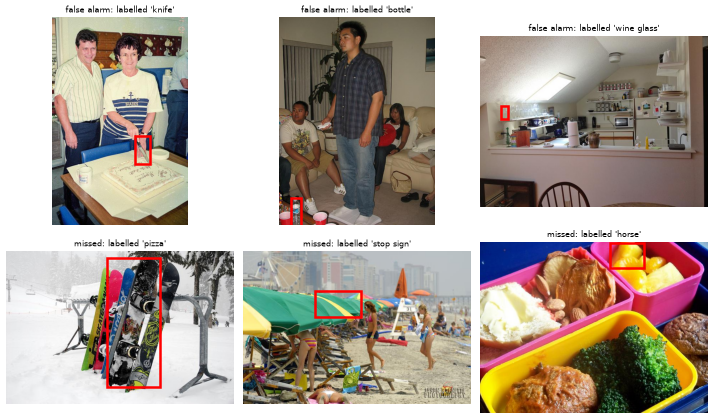


ALL false alarms of seed 0: 83; class size (boxes of that class in the dataset): median 24 for false alarms against median 22 for all untouched boxes
  false alarms whose class has at most 5 boxes: 1 of 83 (untouched boxes in general: 83 of 883)
ALL missed planted mistakes of seed 0: 32; by reason: {'not scored': 31, 'scored, a neighbour carries the class': 1}


In [16]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage

plt.rcParams["figure.dpi"] = 60
r0 = results[0]
damaged0, planted0 = r0["dataset"], r0["plant"]
reported0 = suspects_of(r0["run"])
file_of = {i.image_id: Path(i.file_path).name for i in clean.images}
image_of = {i.image_id: i for i in clean.images}
ann_of = {a.ann_id: a for a in damaged0.annotations}
rng = np.random.default_rng(2026)
false_alarms = sorted(set(reported0) - set(planted0))
missed = sorted(set(planted0) - set(reported0))
picks = [("false alarm", a) for a in rng.choice(false_alarms, 3, replace=False)] + [
    ("missed", a) for a in rng.choice(missed, 3, replace=False)
]

ids = list(embeddings.ids)
annotated = sorted({a.image_id for a in damaged0.annotations})
mat = embeddings.matrix[[ids.index(i) for i in annotated]].astype(np.float64)
mat /= np.linalg.norm(mat, axis=1, keepdims=True)
sims = mat @ mat.T
np.fill_diagonal(sims, -np.inf)
carried = {i: set() for i in annotated}
for a in damaged0.annotations:
    carried[a.image_id].add(a.category_id)


def explain(image_id):
    n = annotated.index(image_id)
    order = np.lexsort((np.arange(len(annotated)), -sims[n]))[: DEFAULT.suspect_k]
    usable = [j for j in order if sims[n, j] >= DEFAULT.suspect_min_similarity]
    hist = Counter(c for j in usable for c in carried[annotated[j]])
    return usable, hist


fig, axes = plt.subplots(2, 3, figsize=(12, 7.4))
for ax, (kind, ann_id) in zip(axes.flat, picks, strict=True):
    a = ann_of[str(ann_id)]
    img = image_of[a.image_id]
    ax.imshow(PILImage.open(img.file_path))
    x1, y1, x2, y2 = a.bbox_xyxy_abs
    ax.add_patch(
        plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=3)
    )
    usable, hist = explain(a.image_id)
    ax.set_title(f"{kind}: labelled '{name_of[a.category_id]}'", fontsize=10)
    ax.axis("off")
    old = planted0.get(str(ann_id))
    why = (
        f"was '{name_of[old[0]]}' before the planted change; " if old else "original label; "
    ) + (
        f"{len(usable)} usable neighbours, {hist[a.category_id]} carry its class"
        if len(usable) >= DEFAULT.suspect_min_neighbours
        else f"only {len(usable)} neighbours close enough: not scored"
    )
    print(f"{kind:<12} {file_of[a.image_id]:<19} labelled '{name_of[a.category_id]}': {why}")
    if usable:
        print(
            f"{'':<12} neighbour classes: "
            + ", ".join(f"{name_of[c]} x{n}" for c, n in hist.most_common(4))
        )
plt.tight_layout()
plt.show()

size_of = Counter(a.category_id for a in clean.annotations)
fa_sizes = sorted(size_of[ann_of[i].category_id] for i in false_alarms)
untouched_sizes = sorted(
    size_of[a.category_id] for a in damaged0.annotations if a.ann_id not in planted0
)
print()
print(
    f"ALL false alarms of seed 0: {len(false_alarms)}; class size (boxes of that class in the dataset): median {int(np.median(fa_sizes))} for false alarms against median {int(np.median(untouched_sizes))} for all untouched boxes"
)
print(
    f"  false alarms whose class has at most 5 boxes: {sum(s <= 5 for s in fa_sizes)} of {len(fa_sizes)} (untouched boxes in general: {sum(s <= 5 for s in untouched_sizes)} of {len(untouched_sizes)})"
)
by_reason = Counter(
    "not scored" if i in r0["unscored_ids"] else "scored, a neighbour carries the class"
    for i in missed
)
print(f"ALL missed planted mistakes of seed 0: {len(missed)}; by reason: {dict(by_reason)}")

**What this shows.** Each panel is a photo with the box in question outlined in red; the lines above the picture give the recomputed evidence. The statistics after the picture
describe every false alarm and every miss of seed 0, so the six examples can be placed in the whole.

## 11. Verdict, computed from the numbers above

In [17]:
from IPython.display import Markdown, display

p, rc, rc_s = mean("precision"), mean("recall"), mean("recall_scorable")
fpr, fpr_s = mean("fpr"), mean("fpr_scorable")
lift_all, lift_scorable = float(np.mean(lifts)), float(np.mean(lifts_scorable))
best = max(grid.items(), key=lambda kv: kv[1]["recall"])
lines = [
    f"- Coverage: the check scored {mean('scored'):.0f} of {len(clean.annotations)} boxes ({coverage:.0%}) at the default thresholds; the other {mean('not_scored'):.0f} boxes have too few close neighbours and are not scored. Those are a limit of coverage, not misses of the rule.",
    f"- Over all boxes: {mean('reported'):.0f} reports per run on average, {mean('found'):.0f} of the {mean('planted'):.0f} planted mistakes among them: recall {rc:.2f}, precision {p:.2f}, false-positive rate {fpr:.2f}.",
    f"- Over scorable boxes only: recall {rc_s:.2f}, false-positive rate {fpr_s:.2f}.",
    f"- Precision against the base rate: {lift_all:.1f} times the all-boxes base rate (per seed {min(lifts):.1f} to {max(lifts):.1f}) and {lift_scorable:.1f} times the scorable-boxes base rate (per seed {min(lifts_scorable):.1f} to {max(lifts_scorable):.1f}); five seeds, no confidence interval.",
    f"- The untouched dataset gets {untouched['reported']} reports of {len(clean.annotations)} boxes ({untouched['fpr']:.2f} over all, {untouched['fpr_scorable']:.2f} over scorable boxes); some may be real label errors, which this measurement cannot tell.",
    f"- Same-photo confusions: recall {same_recall:.2f} over all boxes and {same_recall_scorable:.2f} over scorable boxes, against {random_recall:.2f} and {random_recall_scorable:.2f} for random classes.",
    f"- Loosest setting tried (tuned on this data): recall {best[1]['recall']:.2f} at precision {best[1]['precision']:.2f} and false-positive rate {best[1]['fpr']:.2f}.",
]
if p < 0.5 or rc < 0.5:
    verdict = "**Verdict: weak on this dataset.** "
    if p < 0.5:
        verdict += f"{1 - p:.0%} of what it reports is not a planted mistake (a lower bound on false alarms, because the original labels may hold real errors). "
    if rc < 0.5:
        verdict += f"It finds {rc:.0%} of the planted mistakes over all boxes and {rc_s:.0%} over the boxes it can score. "
    verdict += "Treat a report as a short list of leads to look at, never as a list of errors, and do not use it as a gate on a dataset of this size and kind."
else:
    verdict = "**Verdict: useful on this dataset.** Most reported boxes are planted mistakes and most planted mistakes are reported."
display(Markdown("\n".join(lines) + "\n\n" + verdict))

- Coverage: the check scored 296 of 929 boxes (32%) at the default thresholds; the other 633 boxes have too few close neighbours and are not scored. Those are a limit of coverage, not misses of the rule.
- Over all boxes: 96 reports per run on average, 10 of the 46 planted mistakes among them: recall 0.23, precision 0.11, false-positive rate 0.10.
- Over scorable boxes only: recall 0.83, false-positive rate 0.30.
- Precision against the base rate: 2.2 times the all-boxes base rate (per seed 1.5 to 2.9) and 2.5 times the scorable-boxes base rate (per seed 2.0 to 2.8); five seeds, no confidence interval.
- The untouched dataset gets 90 reports of 929 boxes (0.10 over all, 0.30 over scorable boxes); some may be real label errors, which this measurement cannot tell.
- Same-photo confusions: recall 0.09 over all boxes and 0.28 over scorable boxes, against 0.23 and 0.83 for random classes.
- Loosest setting tried (tuned on this data): recall 0.84 at precision 0.12 and false-positive rate 0.33.

**Verdict: weak on this dataset.** 89% of what it reports is not a planted mistake (a lower bound on false alarms, because the original labels may hold real errors). It finds 23% of the planted mistakes over all boxes and 83% over the boxes it can score. Treat a report as a short list of leads to look at, never as a list of errors, and do not use it as a gate on a dataset of this size and kind.

**What this shows.** The wording follows from the thresholds in the code, not from a sentence written in advance.

## What you learned

- `label_noise` is built on what the audit already has: one embedding per photo. It does not look inside the box, so what it can say is that
  similar photos do not carry a class, which also holds for a rare but correct object.
- It is deterministic, counts what it cannot score and what its caps hide, and does not report a pass when it did not run.
- Every measure here has two denominators, because boxes the check cannot score are neither found nor falsely reported; the cells above print both.
- The cells above report how the check behaves on a confusion with a class of the same photo, and which settings change recall and false alarms.
  Box-level embeddings, class-aware calibration and confident learning are possible next steps and are not built; see the decision record.
- The planted mistakes, thresholds and seeds are in the cells above, so every number can be reproduced.